# PCA 降維對手寫數字辨識效果的影響

讓電腦看圖片，猜出上面是 **0 到 9 的哪個數字**。

- **PCA**：把圖片的資訊濃縮成少數重點。
- **KNN**：找最像的練習圖片，參考它們的答案。

我們想知道：**資訊變少後，還能猜得準嗎？**


In [1]:
# ===== 準備工作：拿好工具 =====

# A 載入讀檔和顯示結果的工具。
from pathlib import Path
from collections import Counter
import csv
import html
import sys

from IPython.display import HTML, Image, Markdown, display

# B 找到這份專題放在哪裡。
candidates = [
    Path.cwd(),
    Path.cwd().parent,
    Path.cwd() / "Final Project" / "Handwritten_Digits_PCA_KNN",
]
PROJECT_ROOT = next(
    (path for path in candidates
     if (path / "src" / "digits_experiment.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("請從專題根目錄或 notebooks 目錄執行。")
PROJECT_ROOT = PROJECT_ROOT.resolve()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

# C 拿出讀圖、分題和訓練用的小工具。
from digits_experiment import load_dataset, run_experiment, split_dataset

OUTPUT = PROJECT_ROOT / "outputs"


# D 做一個顯示成績表的小工具。
def show_csv(filename, max_rows=None):
    """把檔案裡的成績排成表格。"""
    # 先把表格資料讀進來。
    with (OUTPUT / filename).open(
        encoding="utf-8-sig", newline=""
    ) as stream:
        rows = list(csv.reader(stream))
    header, body_rows = rows[0], rows[1:]
    # 表格太長時，只取前幾列。
    if max_rows is not None:
        body_rows = body_rows[:max_rows]
    # 把標題和每一列排好，再顯示出來。
    header_html = "".join(
        f"<th>{html.escape(value)}</th>" for value in header
    )
    body_html = "".join(
        "<tr>"
        + "".join(f"<td>{html.escape(value)}</td>" for value in row)
        + "</tr>"
        for row in body_rows
    )
    display(HTML(
        '<div style="overflow-x:auto"><table>'
        f"<thead><tr>{header_html}</tr></thead>"
        f"<tbody>{body_html}</tbody></table></div>"
    ))
    if max_rows is not None and len(rows) - 1 > max_rows:
        print(f"顯示前 {max_rows} 列；完整結果保存在 {filename}。")


# E 確認工具已經準備好。
print("專題目錄：", PROJECT_ROOT)
print("執行 Python：", sys.version.split()[0])


專題目錄： /Users/liangzhezhi/Desktop/NTU_AI-class/AI_Programing/Final Project/Handwritten_Digits_PCA_KNN
執行 Python： 3.14.6


## 1 拿出數字圖片

共有 **1,797 張圖片**。每張由 8×8＝64 個小格子組成。
把亮度縮到 0～1，再把小格子排成一列，方便電腦比較。


In [2]:
# ===== 第 1 步：拿出數字圖片 =====

# 1-1 X 是整理好的圖片，y 是正確答案。
X, y, images = load_dataset()
# 1-2 看圖片的大小和亮度範圍。
print("影像陣列形狀：", images.shape)
print("展平特徵形狀：", X.shape)
print("像素值範圍：", float(X.min()), "～", float(X.max()))
# 1-3 數一數，每個數字有幾張圖。
print("各類樣本數：")
for digit, count in sorted(Counter(int(value) for value in y).items()):
    print(f"數字 {digit}：{count} 張")


影像陣列形狀： (1797, 8, 8)
展平特徵形狀： (1797, 64)
像素值範圍： 0.0 ～ 1.0
各類樣本數：
數字 0：178 張
數字 1：182 張
數字 2：177 張
數字 3：183 張
數字 4：181 張
數字 5：182 張
數字 6：181 張
數字 7：179 張
數字 8：174 張
數字 9：180 張


## 2 分成練習題和考試題

- **練習題：1,437 張**，約八成，讓電腦學習。
- **考試題：360 張**，約兩成，最後才拿出來。

兩邊不能放同一張圖，也不能先偷看考試答案來挑設定。


In [3]:
# ===== 第 2 步：分開練習題和考試題 =====

# 2-1 約八成拿來練習，兩成留到最後考試。
train_idx, test_idx = split_dataset(y)
# 2-2 看兩邊各有幾張，確認沒有重複圖片。
print("訓練資料：", X[train_idx].shape)
print("保留測試資料：", X[test_idx].shape)
print("訓練與測試索引交集：", len(set(train_idx) & set(test_idx)))
# 2-3 確認每個數字都有分到練習題和考試題。
for digit in range(10):
    train_count = int((y[train_idx] == digit).sum())
    test_count = int((y[test_idx] == digit).sum())
    print(f"數字 {digit}：訓練 {train_count} 張，測試 {test_count} 張")


訓練資料： (1437, 64)
保留測試資料： (360, 64)
訓練與測試索引交集： 0
數字 0：訓練 142 張，測試 36 張
數字 1：訓練 146 張，測試 36 張
數字 2：訓練 142 張，測試 35 張
數字 3：訓練 146 張，測試 37 張
數字 4：訓練 145 張，測試 36 張
數字 5：訓練 145 張，測試 37 張
數字 6：訓練 145 張，測試 36 張
數字 7：訓練 143 張，測試 36 張
數字 8：訓練 139 張，測試 35 張
數字 9：訓練 144 張，測試 36 張


## 3 讓電腦練習，再考試

先用練習題挑設定，選好後才做最後的考試。
也讓「不用 PCA 濃縮資訊」的做法參加比較。

下面這格會完成整套實驗，後面再一起看成績。


In [4]:
# ===== 第 3 步：完成練習和最後的考試 =====

# 3-1 先用三次小考挑設定，再做最後的考試。
metrics = run_experiment(PROJECT_ROOT)
# 3-2 看結果存在哪裡、用了多少張圖。
print("結果目錄：", OUTPUT)
print("訓練樣本：", metrics["train_samples"])
print("測試樣本：", metrics["test_samples"])


Training images: 1437; held-out test images: 360
Best PCA + KNN: {'knn__n_neighbors': 1, 'pca__n_components': 30}
Training CV accuracy: 98.5386%
PCA + KNN test accuracy: 98.3333% (354/360)
Pixel-space KNN test accuracy: 98.6111% (355/360)
結果目錄： /Users/liangzhezhi/Desktop/NTU_AI-class/AI_Programing/Final Project/Handwritten_Digits_PCA_KNN/outputs
訓練樣本： 1437
測試樣本： 360


## 4 看看圖片的重點

**平均圖**是很多練習圖片的平均樣子。
**主成分圖**是 PCA 找出的變化圖樣，不代表某一個數字。


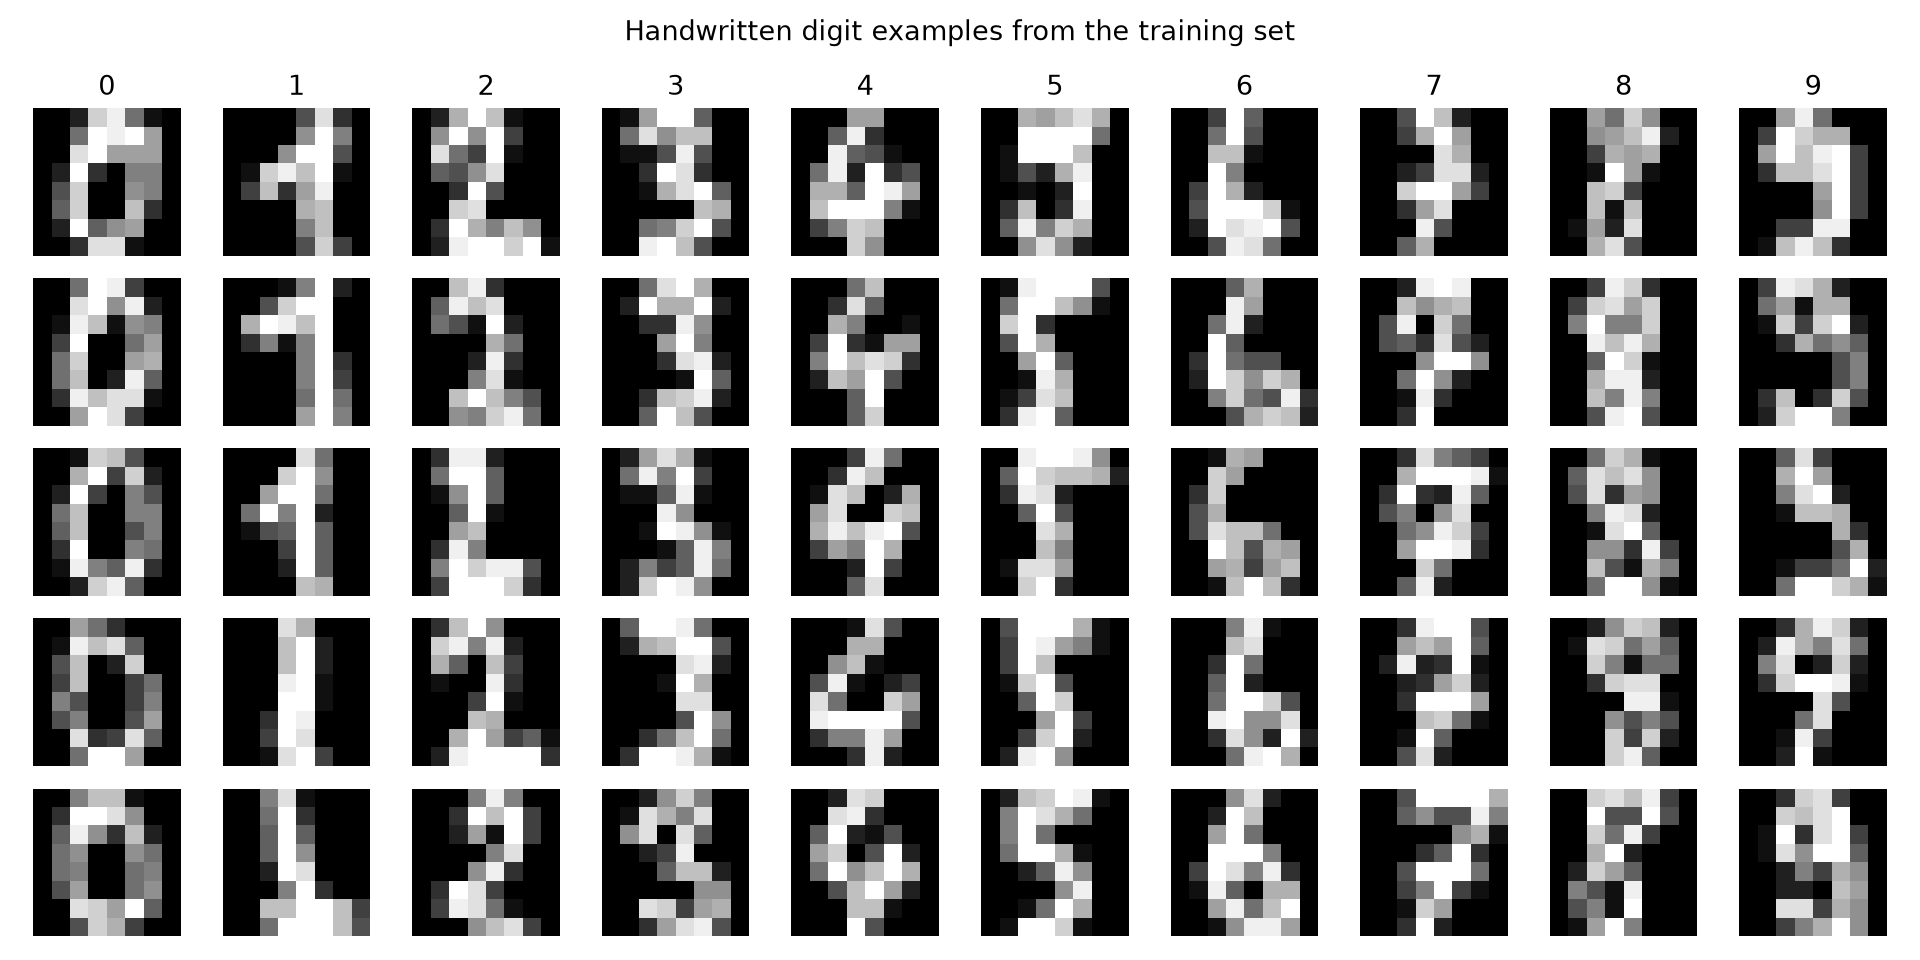

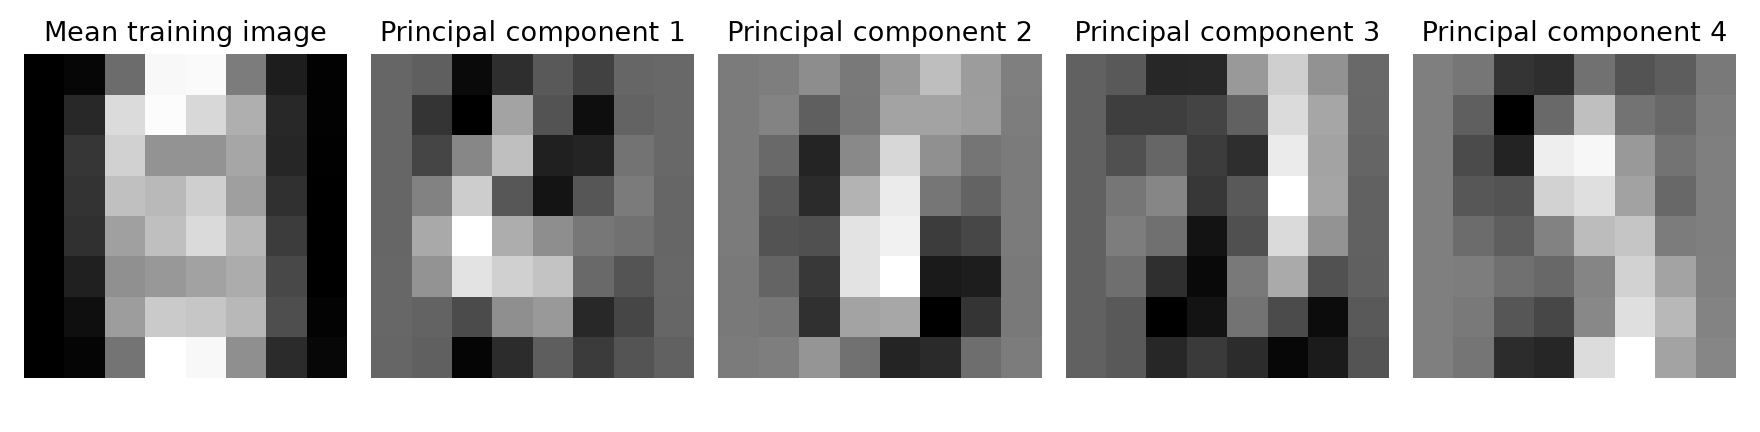

In [5]:
# ===== 第 4 步：看看圖片和 PCA 的重點 =====

# 4-1 先看零到九的練習圖片。
display(Image(filename=str(OUTPUT / "digit_samples.png")))
# 4-2 再看平均圖和前四個重點圖樣。
display(Image(filename=str(OUTPUT / "pca_components.png")))


## 5 用少數重點把圖片拼回來

重點越多，通常能拼回更多細節。
**MSE 是還原差距，越小越接近原圖。**

注意：拼得像，不一定猜得準。


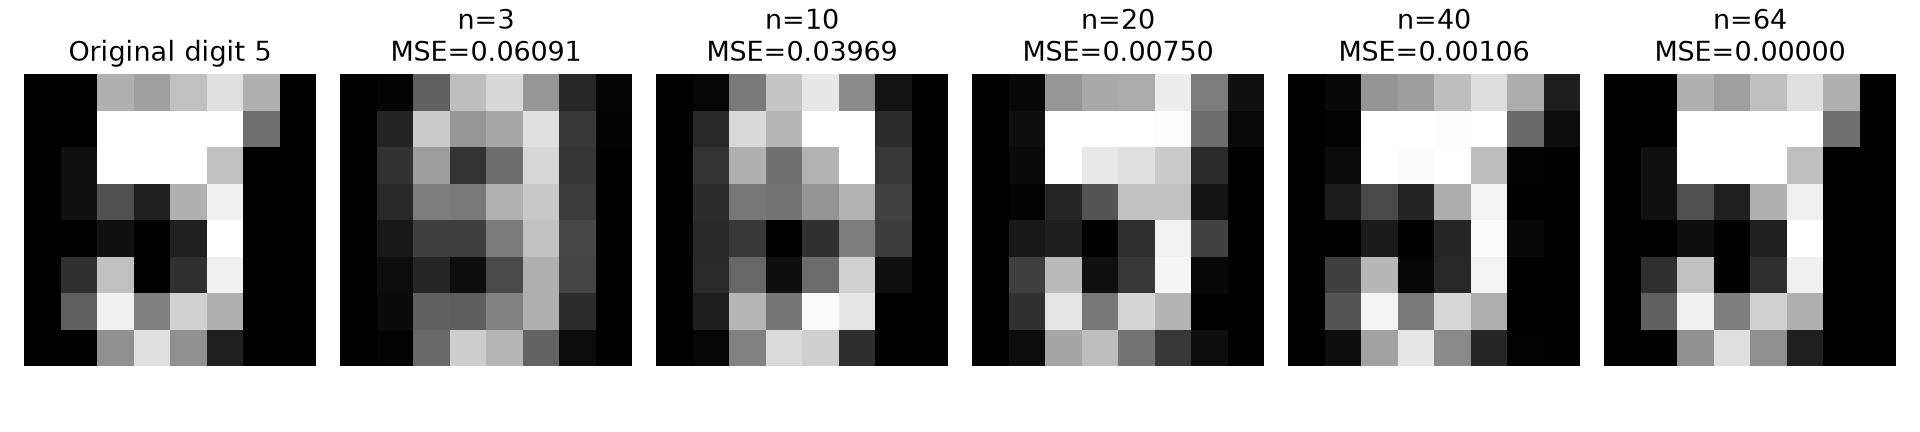

pca_components,normalized_pixel_mse
3,0.060914883583113456
10,0.03968569044104788
20,0.007497290897329749
40,0.0010551777520466028
64,1.2720985314730457e-31


In [6]:
# ===== 第 5 步：把圖片拼回來 =====

# 5-1 用不同數量的重點，看看能拼回多少細節。
display(Image(filename=str(OUTPUT / "pca_reconstruction.png")))
# 5-2 看還原差距，數字越小越像原圖。
show_csv("pca_reconstruction_mse.csv")


## 6 做三次小考，挑出好設定

把練習題分成三組，輪流用兩組學習、一組小考。
比較 **15 種設定**，挑小考平均分數最高的。

這裡還沒有看最後的考試圖片。


pca_components,training_explained_variance,knn_neighbors,fold_1_accuracy,fold_2_accuracy,fold_3_accuracy,mean_accuracy,std_accuracy,rank
10,0.7387555124590537,1,0.9665970772442589,0.9665970772442589,0.9749478079331941,0.9693806541405706,0.003936572198672467,15
20,0.894535906398146,1,0.9895615866388309,0.9791231732776617,0.9791231732776617,0.9826026443980513,0.004920715248340636,7
30,0.9593762850283643,1,0.9874739039665971,0.9812108559498957,0.9874739039665971,0.9853862212943633,0.0029524291490043504,1
40,0.9883282663922031,1,0.9874739039665971,0.9812108559498957,0.9832985386221295,0.9839944328462074,0.0026037977639345243,3
50,0.9995376473206298,1,0.9874739039665971,0.9832985386221295,0.9853862212943633,0.9853862212943633,0.0017045857639409593,1
10,0.7387555124590537,3,0.9749478079331941,0.9603340292275574,0.9791231732776617,0.9714683368128044,0.008055558039519977,14
20,0.894535906398146,3,0.9874739039665971,0.9812108559498957,0.9812108559498957,0.9832985386221295,0.0029524291490043504,4
30,0.9593762850283643,3,0.9812108559498957,0.9832985386221295,0.9832985386221295,0.9826026443980515,0.0009841430496681167,5
40,0.9883282663922031,3,0.9853862212943633,0.9812108559498957,0.9791231732776617,0.9819067501739736,0.0026037977639345638,8
50,0.9995376473206298,3,0.9874739039665971,0.9812108559498957,0.9791231732776617,0.9826026443980515,0.0035483782279699346,5


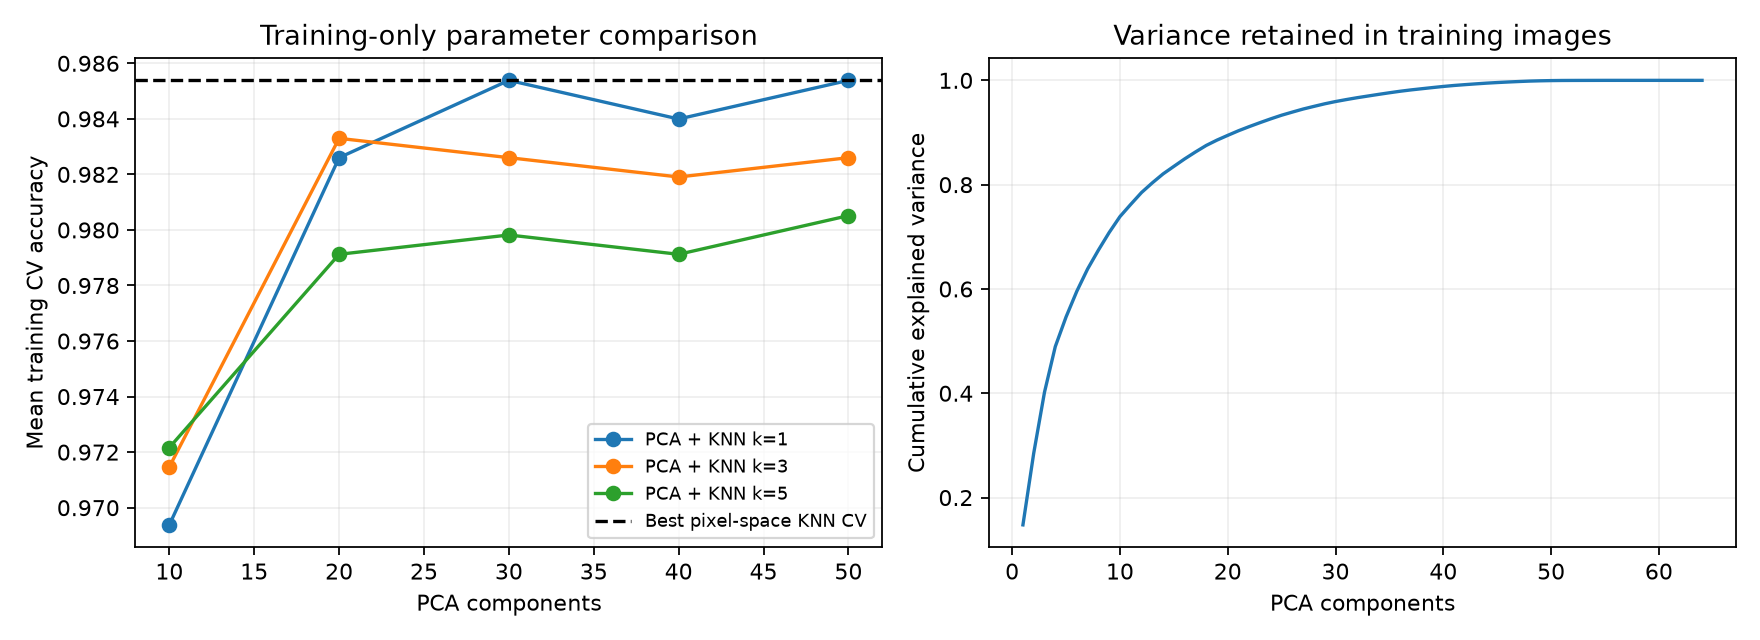

最佳參數： {'knn__n_neighbors': 1, 'pca__n_components': 30}
各折準確率： ['98.75%', '98.12%', '98.75%']
最佳 CV 平均準確率：98.54%
各折標準差：0.30%
訓練準確率：100.00%
保留主成分的累積解釋變異比例： 95.94%


In [7]:
# ===== 第 6 步：比較三次小考的成績 =====

# 6-1 看十五種設定的成績表和比較圖。
show_csv("cv_results.csv")
display(Image(filename=str(OUTPUT / "cv_comparison.png")))
# 6-2 看哪個設定最好，以及三次分數差多少。
print("最佳參數：", metrics["best_params"])
print("各折準確率：", [
    f"{score:.2%}" for score in metrics["cv_best_fold_accuracies"]
])
print(f"最佳 CV 平均準確率：{metrics['cv_best_mean_accuracy']:.2%}")
print(f"各折標準差：{metrics['cv_best_std_accuracy']:.2%}")
print(f"訓練準確率：{metrics['train_accuracy']:.2%}")
# 6-3 看濃縮後保留了多少圖片變化。
print("保留主成分的累積解釋變異比例：",
      f"{metrics['pca_explained_variance_ratio_sum']:.2%}")


## 7 比一比，有沒有 PCA 差在哪

讓兩種方法做同一份考卷：

- **有 PCA**：先濃縮圖片資訊，再猜數字。
- **沒有 PCA**：直接用原本的 64 個小格子猜數字。


In [8]:
# ===== 第 7 步：和不用 PCA 的方法比一比 =====

# 7-1 看不用 PCA 的小考成績。
show_csv("baseline_cv_results.csv")
baseline = metrics["baseline"]
# 7-2 把兩種方法的小考和最後考試成績放在一起。
comparison_rows = [
    ("PCA＋KNN", metrics["cv_best_mean_accuracy"],
     metrics["test_accuracy"], metrics["test_correct"]),
    ("不降維 KNN", baseline["cv_best_mean_accuracy"],
     baseline["test_accuracy"], baseline["test_correct"]),
]
# 7-3 印出分數，再看不用 PCA 時選了哪個設定。
for method, cv_accuracy, test_accuracy, correct in comparison_rows:
    print(f"{method}：CV {cv_accuracy:.2%}；"
          f"測試 {test_accuracy:.2%}（{correct}／"
          f"{metrics['test_samples']}）")
print("不降維 KNN 的最佳參數：", baseline["best_params"])


knn_neighbors,fold_1_accuracy,fold_2_accuracy,fold_3_accuracy,mean_accuracy,std_accuracy,rank
1,0.9874739039665971,0.9832985386221295,0.9853862212943633,0.9853862212943633,0.0017045857639409593,1
3,0.9874739039665971,0.9812108559498957,0.9791231732776617,0.9826026443980515,0.0035483782279699346,2
5,0.9874739039665971,0.9749478079331941,0.9791231732776617,0.9805149617258175,0.005207595527869098,3


PCA＋KNN：CV 98.54%；測試 98.33%（354／360）
不降維 KNN：CV 98.54%；測試 98.61%（355／360）
不降維 KNN 的最佳參數： {'n_neighbors': 1}


## 8 看最後的考試成績

**準確率**就是答對的比例。

- **Precision**：猜是 8 的圖片，有多少真的是 8？
- **Recall**：所有的 8，有多少被找出來？
- **F1**：把猜錯和漏掉的情況一起考慮。

下面的方格表，左邊是真實答案，上面是電腦猜的答案。


**PCA＋KNN 最終測試準確率：98.33%**（354／360 張正確）

**測試 Macro F1：0.9829**

digit,precision,recall,f1-score,support
0,1.0,1.0,1.0,36.0
1,0.9230769230769231,1.0,0.96,36.0
2,1.0,1.0,1.0,35.0
3,1.0,1.0,1.0,37.0
4,0.972972972972973,1.0,0.9863013698630136,36.0
5,1.0,1.0,1.0,37.0
6,1.0,1.0,1.0,36.0
7,1.0,1.0,1.0,36.0
8,0.96875,0.8857142857142857,0.9253731343283582,35.0
9,0.9714285714285714,0.9444444444444444,0.9577464788732394,36.0


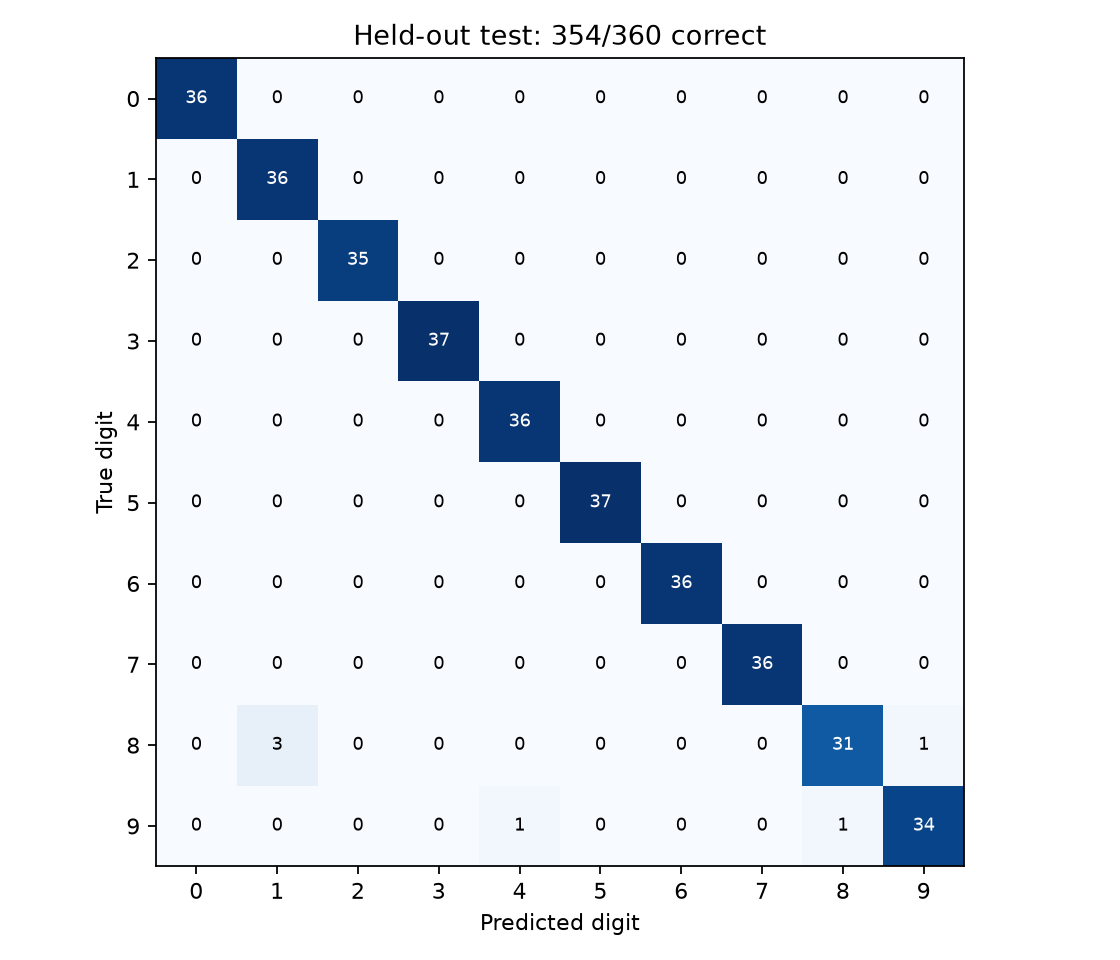

In [9]:
# ===== 第 8 步：公布最後的考試成績 =====

# 8-1 看答對幾張，以及答對的比例。
display(Markdown(
    f"**PCA＋KNN 最終測試準確率：{metrics['test_accuracy']:.2%}**"
    f"（{metrics['test_correct']}／{metrics['test_samples']} 張正確）"
))
display(Markdown(f"**測試 Macro F1：{metrics['test_macro_f1']:.4f}**"))
# 8-2 看零到九各自的成績。
show_csv("classification_report.csv")
# 8-3 看哪些數字容易被猜成別的數字。
display(Image(filename=str(OUTPUT / "confusion_matrix.png")))


## 9 看看電腦猜錯了哪些圖

先看部分考試結果，再看全部猜錯的圖片。
**True 是正確答案，Pred 是電腦猜的答案。**


dataset_index,true_label,predicted_label,baseline_predicted_label,correct
618,5,5,5,True
1427,2,2,2,True
158,8,8,8,True
1256,1,1,1,True
1079,7,7,7,True
648,2,2,2,True
1773,6,6,6,True
1531,2,2,2,True
1063,6,6,6,True
781,5,5,5,True


顯示前 20 列；完整結果保存在 test_predictions.csv。


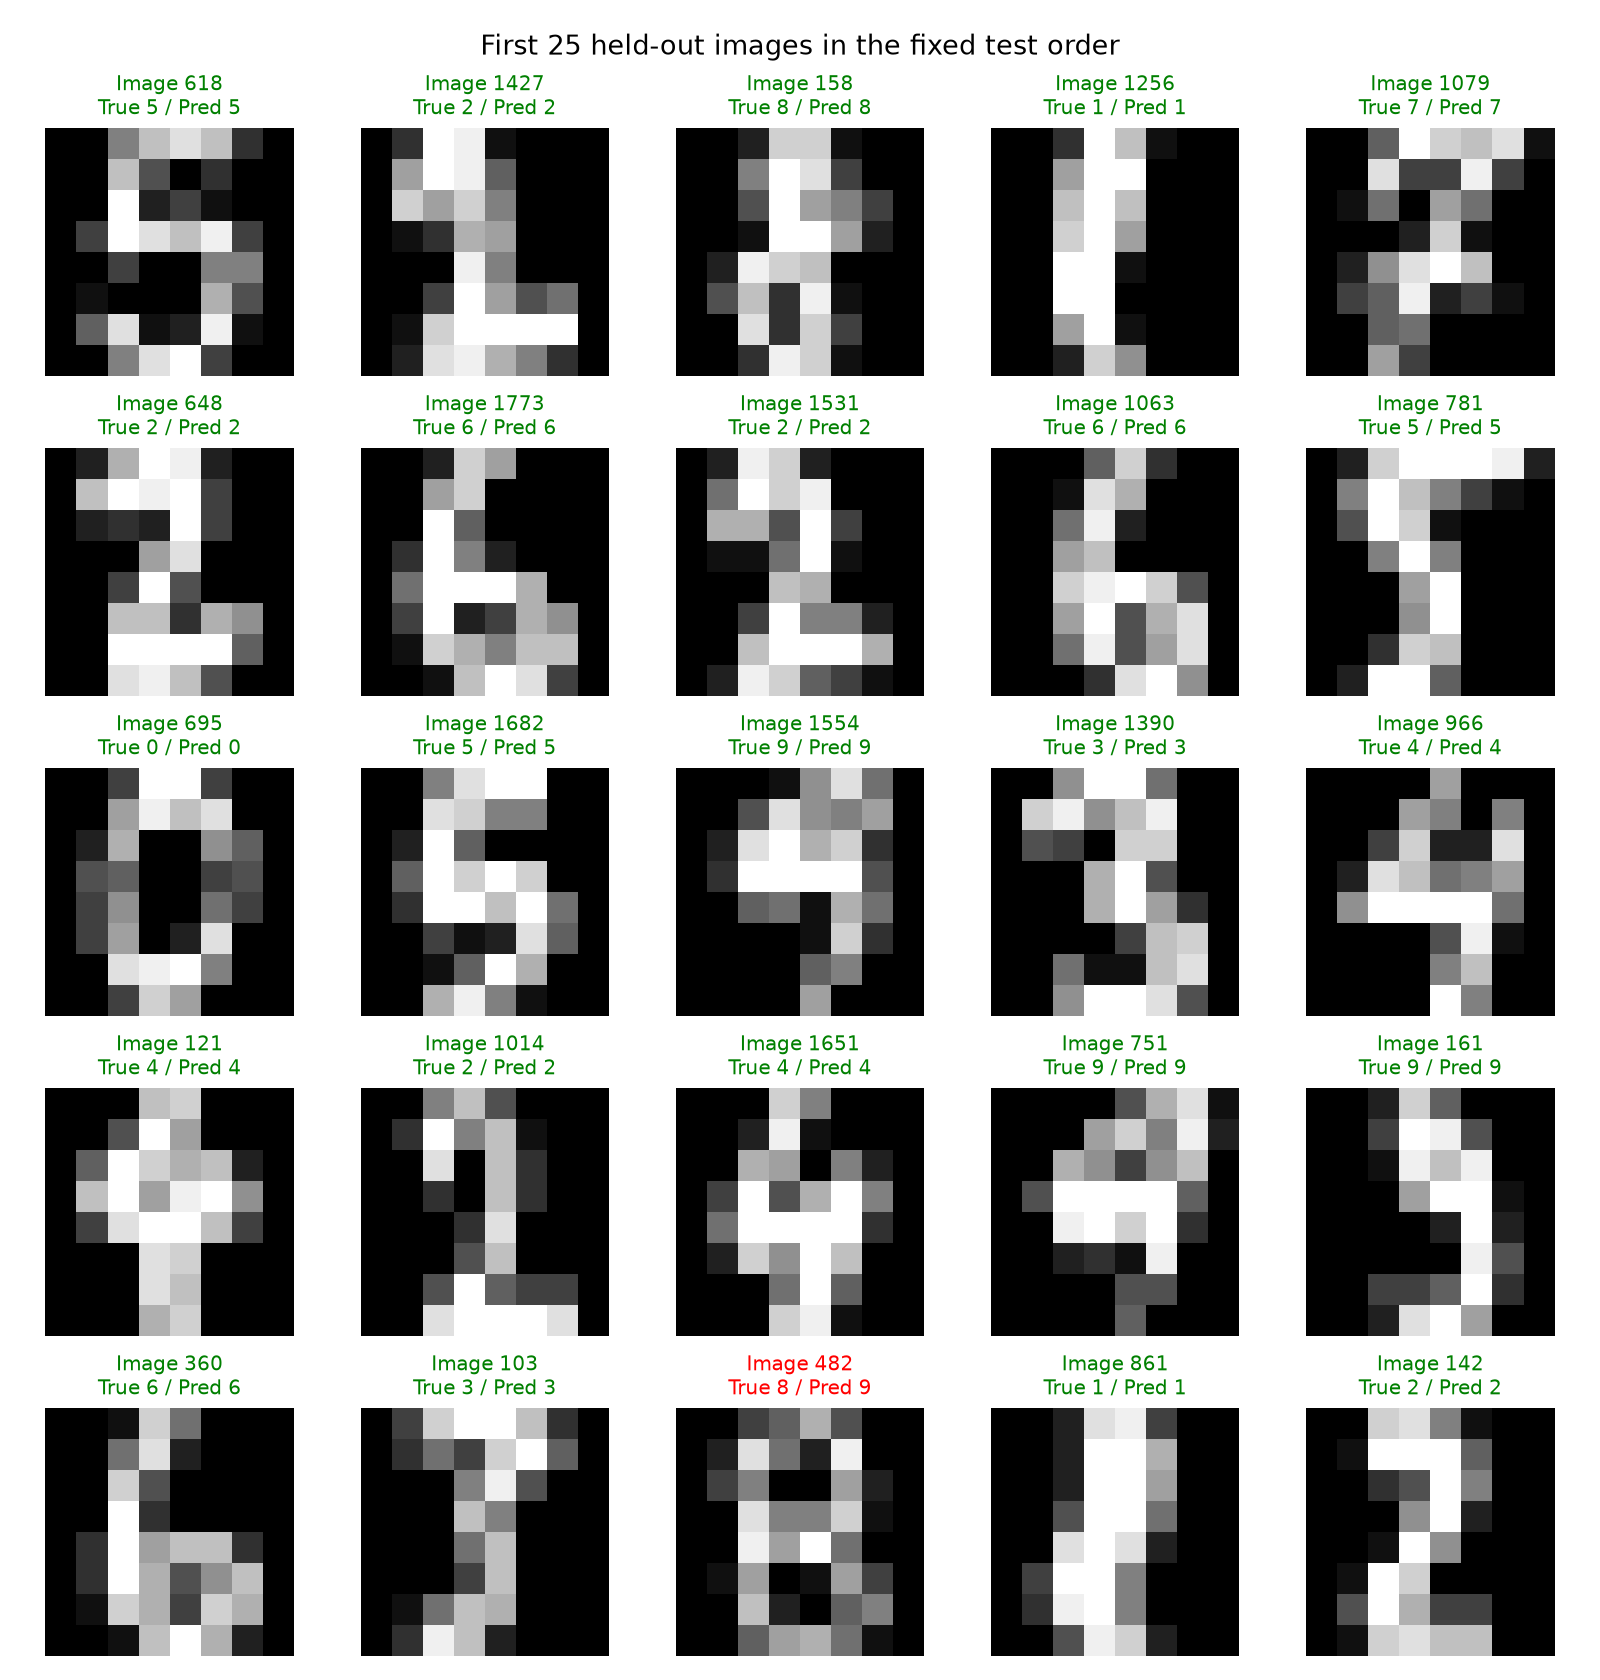

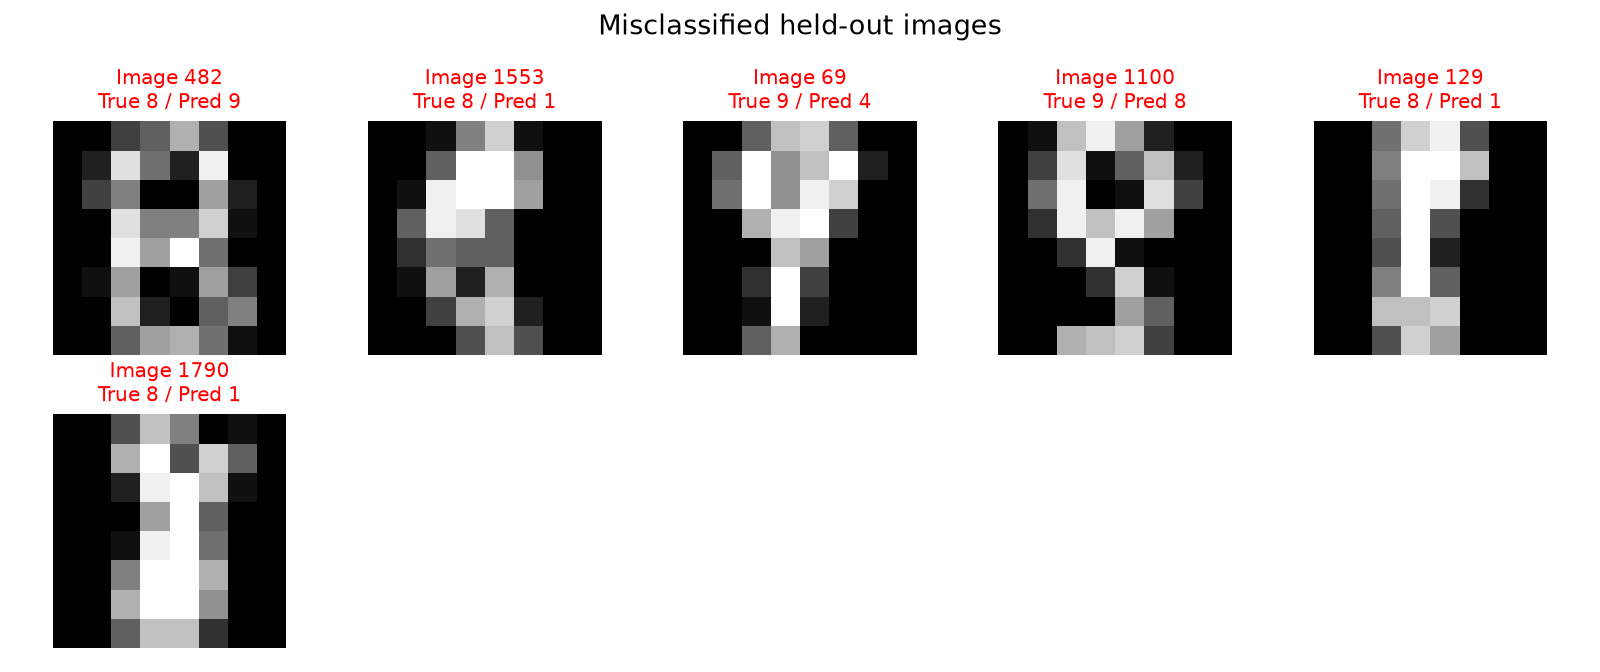

In [10]:
# ===== 第 9 步：檢查每張圖的答案 =====

# 9-1 先列出二十張的正確答案和電腦答案。
show_csv("test_predictions.csv", max_rows=20)
# 9-2 配著圖片看，哪些猜對、哪些猜錯。
display(Image(filename=str(OUTPUT / "test_predictions.png")))
# 9-3 最後只看猜錯的圖片。
display(Image(filename=str(OUTPUT / "misclassified.png")))


## 10 用這次的成績下結論

看猜對多少張，也看圖片濃縮成幾個重點。
如果沒有比較準，就照實寫出來。


In [11]:
# ===== 第 10 步：整理這次發現 =====

# 10-1 算出兩種方法的分數差多少。
pca_score = metrics["test_accuracy"]
baseline_score = metrics["baseline"]["test_accuracy"]
difference = (pca_score - baseline_score) * 100
# 10-2 照實判斷：分數較高、較低，還是一樣。
if difference > 0:
    comparison = f"較不降維 KNN 高 {difference:.2f} 個百分點"
elif difference < 0:
    comparison = f"較不降維 KNN 低 {abs(difference):.2f} 個百分點"
else:
    comparison = "與不降維 KNN 的測試準確率相同"

# 10-3 算出分類用的圖片重點減少多少。
components = metrics["best_params"]["pca__n_components"]
features_saved = 100 * (1 - components / X.shape[1])
# 10-4 把實際成績寫成一句結論。
display(Markdown(
    f"本次以訓練集三折交叉驗證選出的最佳設定為 "
    f"PCA **{components}** 個主成分、KNN 鄰居數 "
    f"**{metrics['best_params']['knn__n_neighbors']}**。"
    f"在保留測試集得到 **{pca_score:.2%}** 準確率，{comparison}。"
    f"分類特徵從 64 維降為 {components} 維，"
    f"減少 **{features_saved:.2f}%** 的特徵維度。"
))


本次以訓練集三折交叉驗證選出的最佳設定為 PCA **30** 個主成分、KNN 鄰居數 **1**。在保留測試集得到 **98.33%** 準確率，較不降維 KNN 低 0.28 個百分點。分類特徵從 64 維降為 30 維，減少 **53.12%** 的特徵維度。